# Simulating the Amplitude-Based Collisionless QLBM with an STL obstacle

Create a 2D staircase cross-section, inspect the obstacle and grid, then run the D2Q9 simulation.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from qiskit_aer import AerSimulator

from qlbm.components import (
    ABDiscreteUniformInitialConditions,
    ABGridMeasurement,
    EmptyPrimitive,
)
from qlbm.components.ab import ABQLBM
from qlbm.infra import QiskitRunner, SimulationConfig
from qlbm.lattice import ABLattice
from qlbm.tools.stl_to_qlbm_config import STLGeometry
from qlbm.tools.utils import create_directory_and_parents


In [24]:
# Position and scale the STL, then take an XY cross-section at z=0.
geometry = STLGeometry(
    "../../stl/sphere.stl",  # Path relative to this notebook's directory
    grid_shape=(64, 32),
    domain_origin=(0, 0),
    object_center=(16, 16, 0),
    object_size=12,
    rotation_deg=(0, 0, 0),
    plane="xy",
    slice_coordinate=0,
)


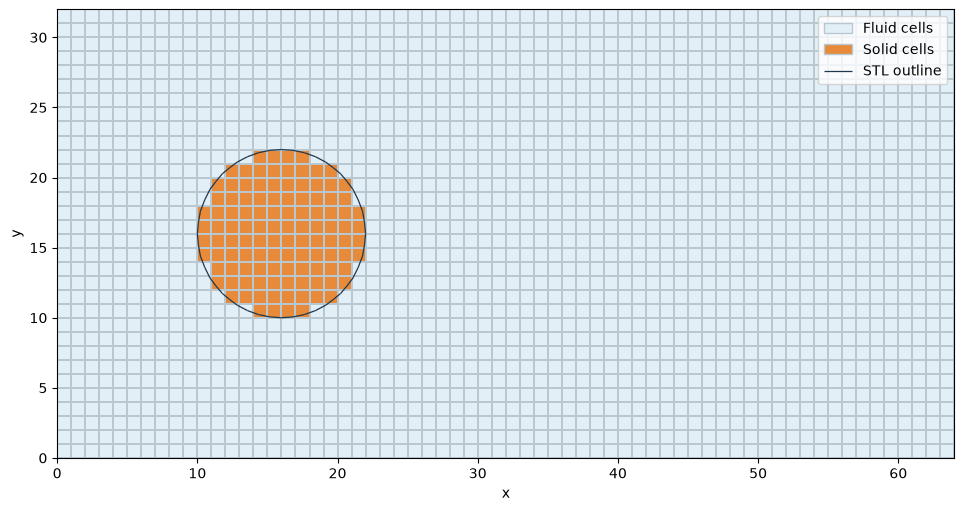

In [25]:
# Inspect the staircase cells and STL outline before building the simulation.
figure = geometry.plot()
plt.show()


In [26]:
config = geometry.to_qlbm_config()
lattice = ABLattice(config)

output_dir = "qlbm-output/ab-d2q9-64x32-stl-sphere-qiskit"
create_directory_and_parents(output_dir)


In [27]:
cfg = SimulationConfig(
    initial_conditions=ABDiscreteUniformInitialConditions(
        lattice,
        [1, 2, 5],  # E, N, and NE
        ([], list(range(5))),  # Span the entire y axis, but nothing on the x axis
    ),
    # The rectangles form one obstacle, so use zone-agnostic bounce-back.
    algorithm=ABQLBM(lattice, use_agnostic_bcs=True),
    postprocessing=EmptyPrimitive(lattice),
    measurement=ABGridMeasurement(lattice),
    target_platform="QISKIT",
    compiler_platform="QISKIT",
    optimization_level=0,
    statevector_sampling=True,
    execution_backend=AerSimulator(method="statevector"),
    sampling_backend=AerSimulator(method="statevector"),
)

In [28]:
cfg.prepare_for_simulation()

In [29]:
# Number of shots to simulate for each timestep when running the circuit
NUM_SHOTS = 2**12

# Number of timesteps to simulate
NUM_STEPS = 30

In [30]:
runner = QiskitRunner(
    cfg,
    lattice,
)


# Run the simulation using statevector snapshots
runner.run(
    NUM_STEPS,  # Number of time steps
    NUM_SHOTS,  # Number of shots per time step
    output_dir,
    statevector_snapshots=True,
)

In [31]:
# Replace this run's separate obstacle overlays with one complete staircase STL.
paraview_dir = Path(output_dir) / "paraview"
geometry.export_paraview_stl(paraview_dir / "geometry.stl")

# Remove only the per-block files produced for this configuration, after export succeeds.
for index, block in enumerate(config["geometry"]):
    (paraview_dir / f"{block['shape']}_{index}.stl").unlink(missing_ok=True)
